# APS360 super-resolution: Colab runner
**Runtime → Change runtime type → T4 GPU.** Run top to bottom.

Everything important (checkpoints, logs, test sets, results) is saved to Google Drive in `aps360_sr_runs/`. If Colab disconnects or you reopen it: run cells 1–3 again (they skip work already done), then rerun the training cell — it resumes from the last checkpoint automatically.

## 1. Drive + code

In [2]:
RUNS = '/content/runs'
!mkdir -p $RUNS
!nvidia-smi -L
import os
if not os.path.exists('/content/sr-project'):
    !git clone -q https://github.com/calikir1/progress-report.git /content/sr-project
%cd /content/sr-project
!git pull -q

GPU 0: Tesla T4 (UUID: GPU-90fcbd7c-4389-6e36-94ba-08066ba5a6b6)
/content/sr-project


## 2. Data (~8 min the first time in a session)

In [3]:
%%bash
set -e
mkdir -p data/benchmark
cd data
[ -d DIV2K_train_HR ] || (wget -q http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip && unzip -q DIV2K_train_HR.zip && rm DIV2K_train_HR.zip)
[ -d DIV2K_valid_HR ] || (wget -q http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip && unzip -q DIV2K_valid_HR.zip && rm DIV2K_valid_HR.zip)
cd benchmark
[ -d Set5 ] || (wget -q https://huggingface.co/datasets/eugenesiow/Set5/resolve/main/data/Set5_HR.tar.gz && tar -xzf Set5_HR.tar.gz && mv Set5_HR Set5)
[ -d Set14 ] || (wget -q https://huggingface.co/datasets/eugenesiow/Set14/resolve/main/data/Set14_HR.tar.gz && tar -xzf Set14_HR.tar.gz && mv Set14_HR Set14)
[ -d B100 ] || (wget -q https://huggingface.co/datasets/eugenesiow/BSD100/resolve/main/data/BSD100_HR.tar.gz && tar -xzf BSD100_HR.tar.gz && mv BSD100_HR B100)
cd /content/sr-project
echo "DIV2K train $(ls data/DIV2K_train_HR | wc -l), valid $(ls data/DIV2K_valid_HR | wc -l), Set5 $(ls data/benchmark/Set5 | wc -l), Set14 $(ls data/benchmark/Set14 | wc -l), B100 $(ls data/benchmark/B100 | wc -l)"

DIV2K train 800, valid 100, Set5 5, Set14 14, B100 100


In [4]:
!python prepare_data.py --src data/DIV2K_train_HR --dst data/div2k_train_npy
!python prepare_data.py --src data/DIV2K_valid_HR --dst data/div2k_valid_npy

100% 800/800 [01:30<00:00,  8.83it/s]
800 images -> data/div2k_train_npy
100% 100/100 [00:11<00:00,  9.06it/s]
100 images -> data/div2k_valid_npy


## 3. Fixed test sets
Built **once**, then always restored from Drive so every experiment uses identical files. The sha256 must end in `a0a003a`.

In [6]:
import os
if os.path.exists(f'{RUNS}/testsets/MANIFEST.txt'):
    !rm -rf testsets && cp -r $RUNS/testsets .
    print('restored test sets from Drive')
else:
    !python make_testsets.py --bench_root data/benchmark --sets Set5 Set14 B100
    !cp -r testsets $RUNS/
!tail -1 testsets/MANIFEST.txt

Set5: 5 images
Set14: 14 images
B100: 100 images
1071 degraded LR images written; sha256 48b3472d23004142e244a42fa0ec4d969a90033472893b9ea986378d1a0a003a
Commit degraded_params.csv and MANIFEST.txt; record the sha256 in the report.
sha256=48b3472d23004142e244a42fa0ec4d969a90033472893b9ea986378d1a0a003a


## 4. One-time checks (already passed — skip after a reset)

In [7]:
# !python smoke_test.py
# !python check_data.py --train data/DIV2K_train_HR data/DIV2K_valid_HR --bench data/benchmark/Set5 data/benchmark/Set14 data/benchmark/B100
!python evaluate.py --methods bicubic --out $RUNS/results
!python count_params.py


PSNR (dB) / SSIM, Y channel, border crop = scale
| Method | Set5 clean | Set14 clean | B100 clean | Set5 degraded | Set14 degraded | B100 degraded |
| --- | --- | --- | --- | --- | --- | --- |
| bicubic | 33.68 / 0.9305 | 30.33 / 0.8700 | 29.56 / 0.8436 | 29.35 / 0.8178 | 27.11 / 0.7337 | 26.78 / 0.6975 |
SRCNN                                             20,099
EDSR-lite, 4 blocks                              483,587
EDSR-lite, 8 blocks                              779,011
EDSR-lite, 9 blocks (param-matched control)      852,867
EDSR-lite, 16 blocks                           1,369,859
Plain, 8 blocks                                  779,011
DegAware-EDSR, 8 blocks                          847,334
  of which estimator 32,995, modulation MLPs 35,328


## 5. Train (~30–45 min each on a T4)
`--resume` continues from the last checkpoint if one exists, otherwise starts fresh. After a disconnect: rerun cells 1–3, then rerun the same training cell. Short on time? Lower `--iters` (15000 still beats bicubic).

In [12]:
!python train.py --name clean --model edsr --iters 30000 --runs $RUNS --resume

edsr: 779,011 parameters | device cuda | amp True
/content/sr-project/train.py:68: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
800 training images | 16000 patches/epoch = 1000 iterations/epoch | 30.0 epochs
iter=100 epoch=0 loss=0.04844 sr_loss=0.04844 deg_loss=0.00000 lr=2.00e-04 elapsed_s=4
iter=200 epoch=0 loss=0.02665 sr_loss=0.02665 deg_loss=0.00000 lr=2.00e-04 elapsed_s=8
iter=300 epoch=0 loss=0.02179 sr_loss=0.02179 deg_loss=0.00000 lr=2.00e-04 elapsed_s=11
iter=400 epoch=0 loss=0.02083 sr_loss=0.02083 deg_loss=0.00000 lr=2.00e-04 elapsed_s=13
iter=500 epoch=0 loss=0.02049 sr_loss=0.02049 deg_loss=0.00000 lr=2.00e-04 elapsed_s=16
iter=600 epoch=0 loss=0.01887 sr_loss=0.01887 deg_loss=0.00000 lr=2.00e-04 elapsed_s=20
iter=700 epoch=0 loss=0.01843 sr_loss=0.01843 deg_loss=0.00000 lr=2.00e-04 elapsed_s=23
iter=800 epoch=0 loss=0.01899 sr_loss=0.01

In [11]:
!python train.py --name degraded --model edsr --degraded --iters 30000 --runs $RUNS --resume

edsr: 779,011 parameters | device cuda | amp True
/content/sr-project/train.py:68: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
800 training images | 16000 patches/epoch = 1000 iterations/epoch | 30.0 epochs
resumed at iteration 30000 (best val 29.705 dB)
done: best val PSNR 29.705 dB -> /content/runs/degraded/best.pt


## 6. Results for the report

In [13]:
!python evaluate.py --methods bicubic $RUNS/clean/best.pt $RUNS/degraded/best.pt --out $RUNS/results
!python plot_curves.py $RUNS/clean $RUNS/degraded
!python visualize.py --set Set14 --image comic.png --condition clean --methods bicubic $RUNS/clean/best.pt $RUNS/degraded/best.pt
!python visualize.py --set B100 --image 253027.png --condition b1.0_n5_q75 --methods bicubic $RUNS/clean/best.pt $RUNS/degraded/best.pt
!mkdir -p $RUNS/results && cp -r results/figures $RUNS/results/

clean: 779,011 params, trained 30000 iterations
degraded: 779,011 params, trained 27500 iterations

PSNR (dB) / SSIM, Y channel, border crop = scale
| Method | Set5 clean | Set14 clean | B100 clean | Set5 degraded | Set14 degraded | B100 degraded |
| --- | --- | --- | --- | --- | --- | --- |
| bicubic | 33.68 / 0.9305 | 30.33 / 0.8700 | 29.56 / 0.8436 | 29.35 / 0.8178 | 27.11 / 0.7337 | 26.78 / 0.6975 |
| clean | 37.57 / 0.9591 | 33.11 / 0.9137 | 31.88 / 0.8961 | 29.32 / 0.8000 | 27.25 / 0.7258 | 26.85 / 0.6909 |
| degraded | 33.31 / 0.9162 | 30.72 / 0.8607 | 30.03 / 0.8336 | 30.96 / 0.8671 | 28.47 / 0.7767 | 27.73 / 0.7362 |
saved results/figures/training_curves.png
saved results/figures/Set14_comic_clean.png
saved results/figures/B100_253027_b1.0_n5_q75.png


| Method | Set5 clean | Set14 clean | B100 clean | Set5 degraded | Set14 degraded | B100 degraded |
| --- | --- | --- | --- | --- | --- | --- |
| bicubic | 33.68 / 0.9305 | 30.33 / 0.8700 | 29.56 / 0.8436 | 29.35 / 0.8178 | 27.11 / 0.7337 | 26.78 / 0.6975 |
| clean | 37.57 / 0.9591 | 33.11 / 0.9137 | 31.88 / 0.8961 | 29.32 / 0.8000 | 27.25 / 0.7258 | 26.85 / 0.6909 |
| degraded | 33.31 / 0.9162 | 30.72 / 0.8607 | 30.03 / 0.8336 | 30.96 / 0.8671 | 28.47 / 0.7767 | 27.73 / 0.7362 |


results/figures/B100_253027_b1.0_n5_q75.png


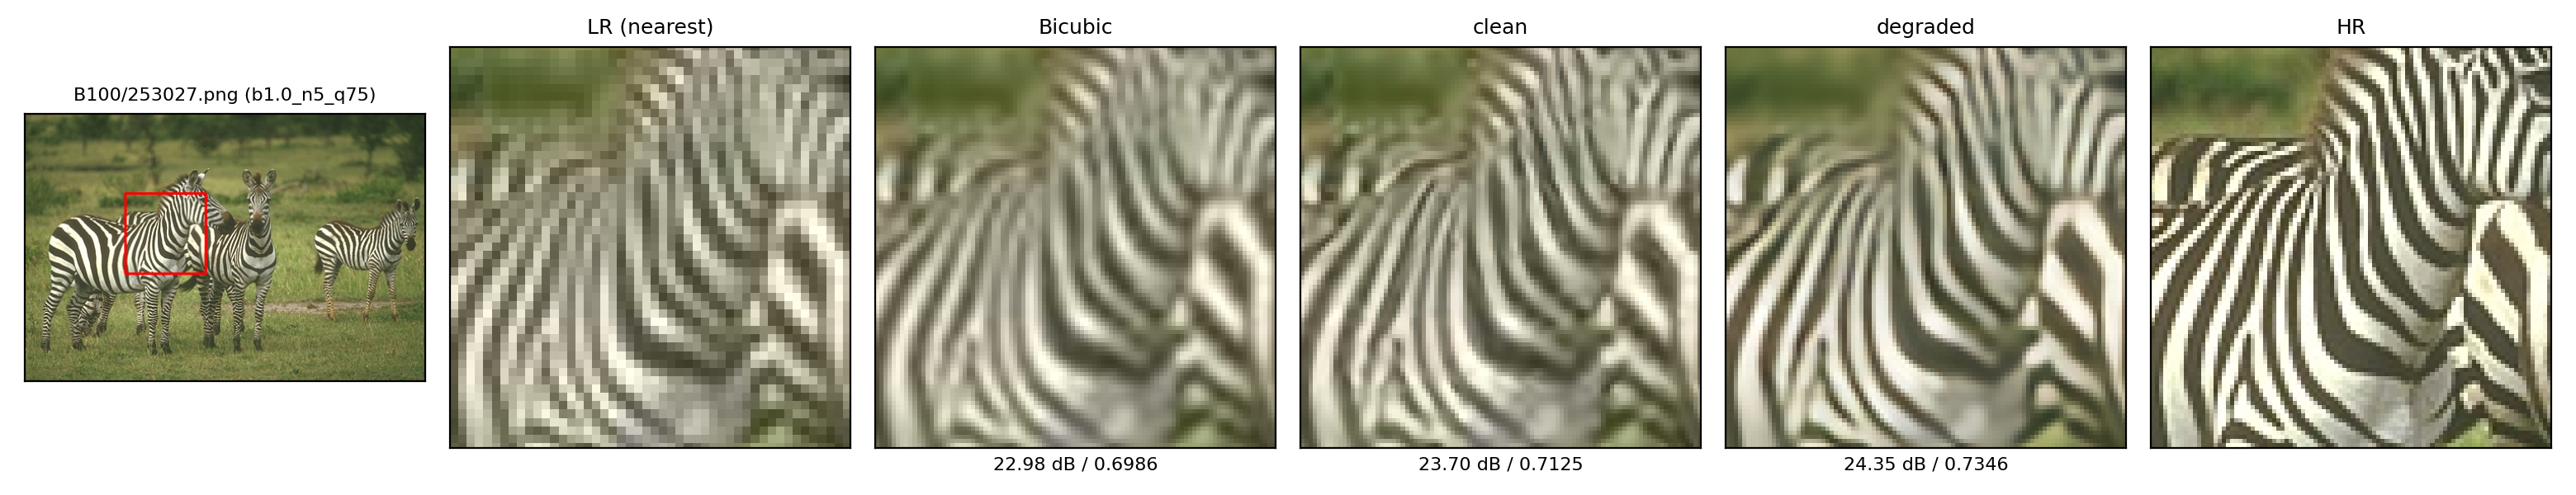

results/figures/Set14_comic_clean.png


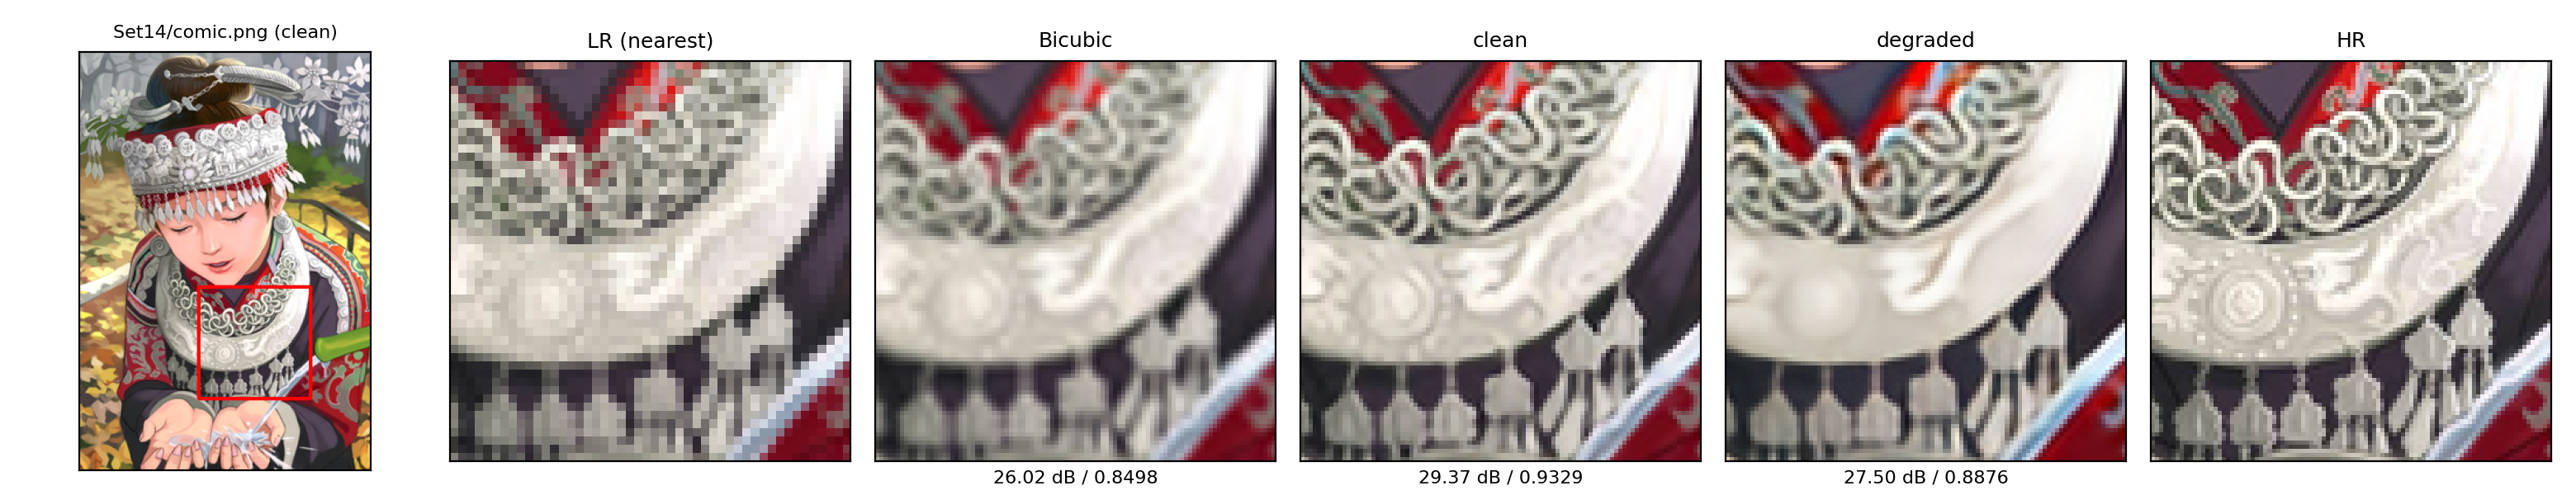

results/figures/training_curves.png


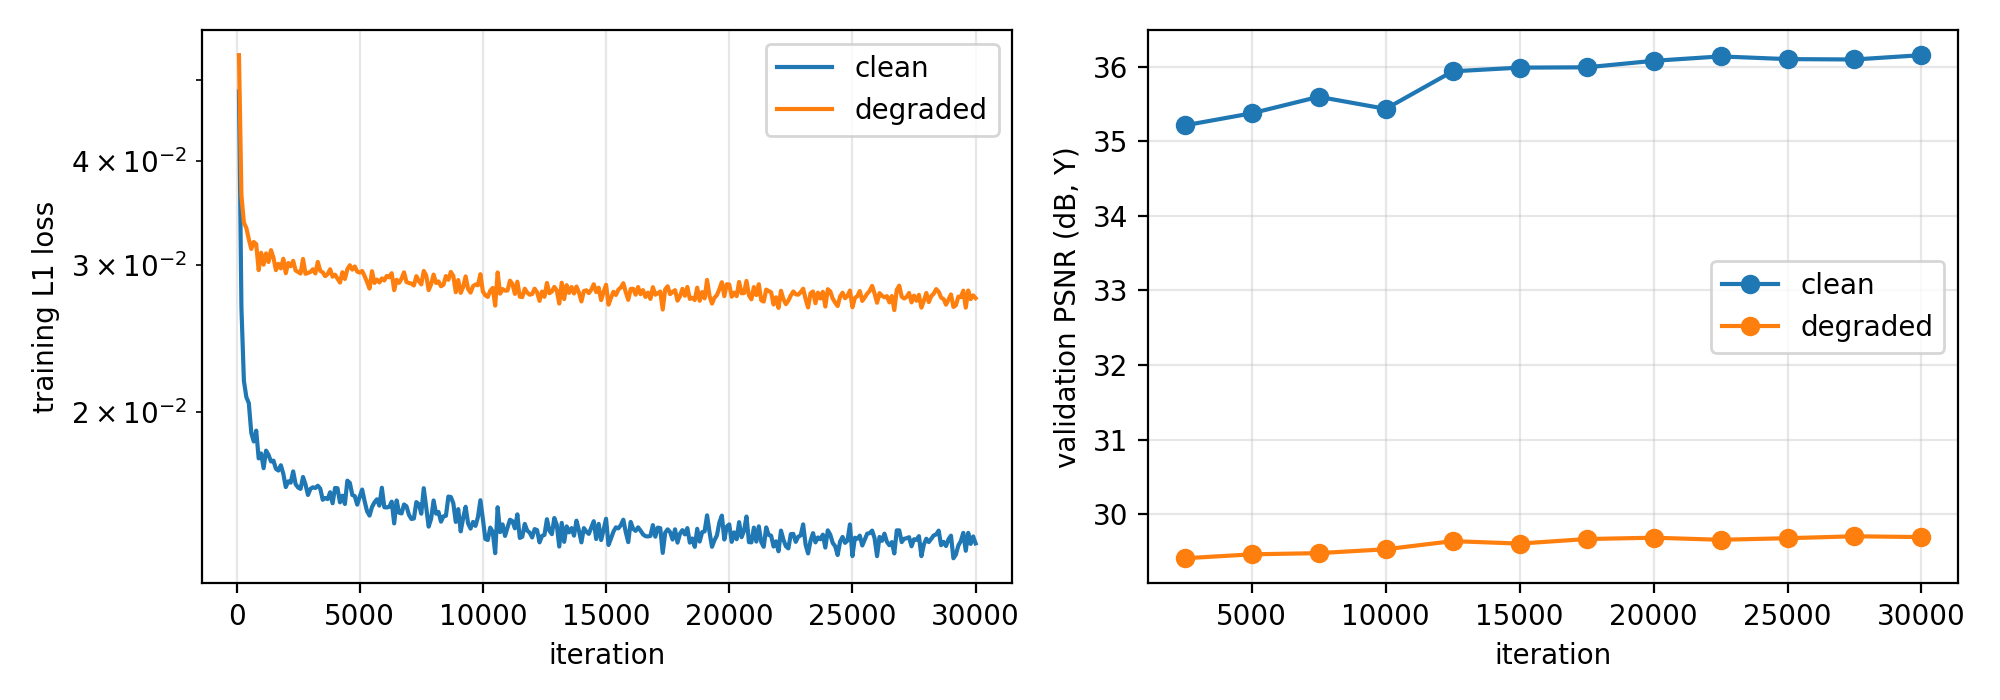

In [14]:
from IPython.display import Image, display, Markdown
import glob
display(Markdown(open(f'{RUNS}/results/table.md').read()))
for f in sorted(glob.glob('results/figures/*.png')): print(f); display(Image(f))

## 7. Download everything for Overleaf + the repo

In [15]:
!cd $RUNS && zip -qr /content/for_report.zip results/table.md results/summary.csv results/figures testsets/degraded_params.csv testsets/MANIFEST.txt clean/log.csv clean/config.json degraded/log.csv degraded/config.json
from google.colab import files
files.download('/content/for_report.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Later (after the progress report)

In [ ]:
# !python train.py --name degaware --model degaware --degraded --iters 30000 --runs $RUNS --resume
# !python train.py --name edsr9_control --model edsr --blocks 9 --degraded --iters 30000 --runs $RUNS --resume
# !python train.py --name srcnn --model srcnn --iters 30000 --runs $RUNS --resume
# !python evaluate.py --methods bicubic $RUNS/clean/best.pt $RUNS/degraded/best.pt $RUNS/degaware/best.pt --out $RUNS/results
# !python visualize.py --phone_dir data/phone --methods bicubic $RUNS/clean/best.pt $RUNS/degraded/best.pt $RUNS/degaware/best.pt